Ques1

In [1]:
!pip install easyocr opencv-python-headless

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 79.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 10.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [easyocr]


Saving medicine_bottle.jpg.jpeg to medicine_bottle.jpg.jpeg
MEDICINE LABEL INFORMATION
-----------------------------------
PARAceTaMol (Confidence: 0.27)
Esk (Confidence: 0.35)
TABLETSLP 650mg (Confidence: 0.46)
8 (Confidence: 0.26)
Crocin (Confidence: 1.00)
650 (Confidence: 1.00)
| (Confidence: 0.11)
STARTST (Confidence: 0.71)
JMIS (Confidence: 0.49)


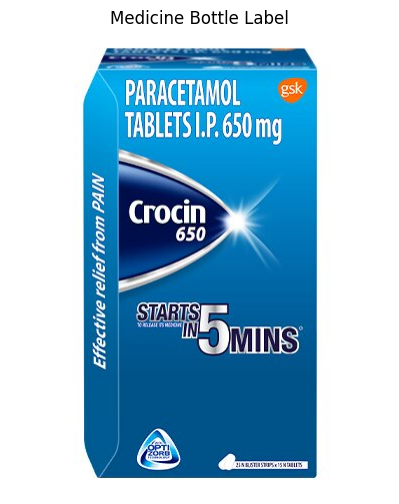

In [5]:

import cv2
import easyocr
import matplotlib.pyplot as plt
from google.colab import files

# Step 1: Upload medicine bottle image
uploaded = files.upload()
image_path = next(iter(uploaded))

# Step 2: Read the image
image = cv2.imread(image_path)

if image is None:
    raise ValueError("Unable to read the uploaded image.")

# Step 3: Convert image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Step 4: Improve image readability
processed = cv2.GaussianBlur(gray, (3, 3), 0)

# Step 5: Initialize OCR reader
reader = easyocr.Reader(['en'], gpu=False)

# Step 6: Extract text
results = reader.readtext(processed)

# Step 7: Display detected text
print("MEDICINE LABEL INFORMATION")
print("-" * 35)

if results:
    for box, text, confidence in results:
        print(f"{text} (Confidence: {confidence:.2f})")
else:
    print("No text detected. Try a clearer image.")

# Step 8: Display the uploaded image
plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Medicine Bottle Label")
plt.axis("off")
plt.show()


Ques2

In [6]:
!pip install -q deepface tf-keras

Saving ErksVfKKJiTfWsr1u2uTienJthzDPKkyLU4KPdDfRZGUbTV96xtjNvHSe03-HFnTo9j1uIRNpk5T1qvvV48ejL1c046kWoxtnmoWpcId8n7xPnv99b0fUcKBWx5l58VrHskJBU_WumyQcu4k0JnGcWBJi6xQbm5o3CeEifZheV0.jpeg to ErksVfKKJiTfWsr1u2uTienJthzDPKkyLU4KPdDfRZGUbTV96xtjNvHSe03-HFnTo9j1uIRNpk5T1qvvV48ejL1c046kWoxtnmoWpcId8n7xPnv99b0fUcKBWx5l58VrHskJBU_WumyQcu4k0JnGcWBJi6xQbm5o3CeEifZheV0.jpeg


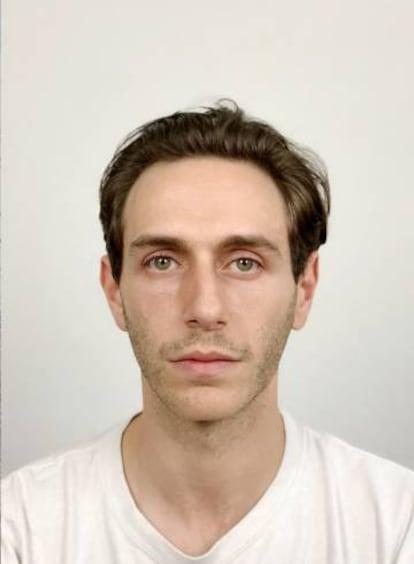

26-10-28 16:51:37 - retinaface.h5 will be downloaded from the url https://github.com/serengil/deepface_models/releases/download/v1.0/retinaface.h5


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/retinaface.h5
To: /root/.deepface/weights/retinaface.h5
100%|██████████| 119M/119M [00:00<00:00, 273MB/s]


26-10-28 16:51:42 - 🔗 facial_expression_model_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5 to /root/.deepface/weights/facial_expression_model_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5
To: /root/.deepface/weights/facial_expression_model_weights.h5
100%|██████████| 5.98M/5.98M [00:00<00:00, 178MB/s]


EMOTION-AWARE COGNITIVE ASSISTANT
----------------------------------------
Predicted emotion: Neutral
Confidence score: 70.54 %

Assistant response:
You appear to have a neutral facial expression.


In [9]:
from google.colab import files
from IPython.display import display
from PIL import Image
from deepface import DeepFace
import numpy as np

# Upload a face image
uploaded = files.upload()
filename = next(iter(uploaded))

image = Image.open(filename).convert("RGB")
display(image)

# Analyze facial expression using an alternative backend to avoid OpenCV 5.x CascadeClassifier error
result = DeepFace.analyze(
    img_path=np.array(image),
    actions=["emotion"],
    enforce_detection=False,
    detector_backend="retinaface"
)

# Handle the result
if isinstance(result, list):
    result = result[0]

emotion = result["dominant_emotion"]
scores = result["emotion"]

print("EMOTION-AWARE COGNITIVE ASSISTANT")
print("-" * 40)
print("Predicted emotion:", emotion.title())
print("Confidence score:", round(scores[emotion], 2), "%")
responses = {
    "happy": "You seem cheerful! Keep enjoying your day.",
    "sad": "You may be feeling low. Would you like to take a break?",
    "angry": "Consider taking a few slow breaths and relaxing.",
    "fear": "Try to find a comfortable place and take a moment.",
    "surprise": "Something may have caught your attention!",
    "disgust": "Would you like to take a moment to reset?",
    "neutral": "You appear to have a neutral facial expression."
}

print("\nAssistant response:")
print(responses.get(
    emotion.lower(),
    "Thank you for sharing your image."
))